# Customer Complaint Classification: SimpleRNN vs LSTM vs GRU vs Fine-tuned Transformer

An end-to-end NLP pipeline that predicts the product category of a customer complaint from its written narrative. Three recurrent models built from scratch (SimpleRNN, LSTM, GRU) are compared with a fine-tuned HuggingFace transformer, and the best model is deployed with Gradio to route new complaints automatically.

## Business goal
Reading and routing complaints by hand is slow and expensive. A model that predicts the right category, with a confidence score, lets confident cases be routed automatically and sends only uncertain cases to a person. Section 13 measures how many complaints can be automated at different confidence levels.

## 1. Setup, settings, and import the dataset
Attach the Kaggle dataset "Consumer Complaints Dataset for NLP" to the notebook and enable a GPU. The cell finds the CSV and detects the narrative column and the category column automatically. If it picks the wrong ones, set `TEXT_COLUMN` and `LABEL_COLUMN`.

device: Tesla T4
/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv  (99.5 MB)
using: /kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv
text column: narrative | label column: product
shape: (162421, 3)


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


missing values:
Unnamed: 0     0
product        0
narrative     10
dtype: int64
rows with text and label: 162411
exact duplicate narratives: 37939
count    162411.0
mean         80.2
std         108.9
min           1.0
25%          27.0
50%          50.0
75%          95.0
max        2685.0
Name: text, dtype: float64


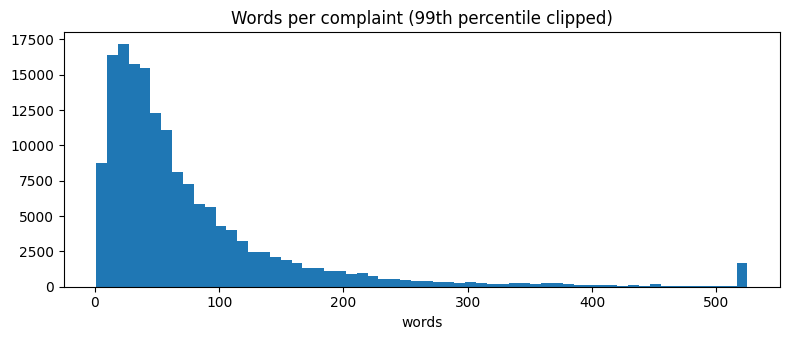

In [1]:
import os, sys, re, time, json, math, copy, random, subprocess, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
T0 = time.time()

SEED = 42
CSV_PATH = None
TEXT_COLUMN = None
LABEL_COLUMN = None
MAX_ROWS = None
MIN_CLASS_SAMPLES = 500
MIN_TOKENS = 3
TRAIN_CAP_PER_CLASS = 8000
EVAL_MAX = 15000
TEST_FRACTION = 0.10
VAL_FRACTION = 0.10

MAX_LEN = 200
VOCAB_SIZE = 30000
MIN_FREQ = 3
EMBED_DIM = 128
HIDDEN = 128
DROPOUT = 0.3
BIDIRECTIONAL = True
RNN_EPOCHS = 8
RNN_BATCH = 128
RNN_LR = 2e-3
PATIENCE = 3

TRANSFORMER_NAME = "distilbert-base-uncased"
TR_MAX_LEN = 256
TR_EPOCHS = 2
TR_BATCH = 16
TR_LR = 3e-5

CUDA = torch.cuda.is_available()
device = torch.device("cuda" if CUDA else "cpu")
torch.backends.cudnn.benchmark = True

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("device:", torch.cuda.get_device_name(0) if CUDA else "CPU only (enable a GPU in Kaggle!)")

root = Path("/kaggle/input")
csv_files = [Path(CSV_PATH)] if CSV_PATH else (sorted(root.rglob("*.csv")) if root.exists() else [])
if not csv_files:
    raise FileNotFoundError("No CSV found. Attach the Consumer Complaints Dataset for NLP to this notebook.")
for path in csv_files:
    print(f"{path}  ({path.stat().st_size / 1e6:.1f} MB)")
CSV_FILE = max(csv_files, key=lambda p: p.stat().st_size)
print("using:", CSV_FILE)

try:
    raw = pd.read_csv(CSV_FILE, nrows=MAX_ROWS, low_memory=False)
except UnicodeDecodeError:
    raw = pd.read_csv(CSV_FILE, nrows=MAX_ROWS, low_memory=False, encoding="latin-1")

def detect_columns(frame):
    sample = frame.head(20000)
    text_like = [c for c in frame.columns if not pd.api.types.is_numeric_dtype(frame[c])]
    if not text_like:
        raise ValueError("No text columns found in the CSV.")
    lengths = {c: sample[c].astype(str).str.len().mean() for c in text_like}
    text_col = TEXT_COLUMN or max(lengths, key=lengths.get)
    candidates = [c for c in text_like if c != text_col and 2 <= sample[c].nunique() <= 60]
    preferred = [c for c in candidates if any(k in c.lower() for k in ("product", "category", "label", "class"))]
    chosen = LABEL_COLUMN or (preferred or candidates or [None])[0]
    if chosen is None:
        raise ValueError("Could not detect the category column. Set LABEL_COLUMN.")
    return text_col, chosen

TEXT_COL, LABEL_COL = detect_columns(raw)
print("text column:", TEXT_COL, "| label column:", LABEL_COL)
print("shape:", raw.shape)
display(raw.head())
print("missing values:")
print(raw.isna().sum())

data = raw[[TEXT_COL, LABEL_COL]].rename(columns={TEXT_COL: "text", LABEL_COL: "label"}).dropna()
data["text"] = data["text"].astype(str).str.strip()
data["label"] = data["label"].astype(str).str.strip()
data = data[data["text"].str.len() > 0].reset_index(drop=True)
print("rows with text and label:", len(data))
print("exact duplicate narratives:", int(data["text"].duplicated().sum()))

word_counts = data["text"].str.split().str.len()
print(word_counts.describe().round(1))
fig, axis = plt.subplots(figsize=(8, 3.5))
axis.hist(word_counts.clip(upper=word_counts.quantile(0.99)), bins=60, color="tab:blue")
axis.set_title("Words per complaint (99th percentile clipped)")
axis.set_xlabel("words")
plt.tight_layout()
plt.show()

## 2. Analyze class distribution
A strong imbalance means plain accuracy can hide poor results on small classes, so macro metrics are reported next to accuracy. Very small classes are removed because they cannot be split and evaluated reliably.

,count,percent
label,,
credit_reporting,91172,56.14
debt_collection,23148,14.25
mortgages_and_loans,18990,11.69
credit_card,15566,9.58
retail_banking,13535,8.33


imbalance ratio (largest / smallest class): 6.7


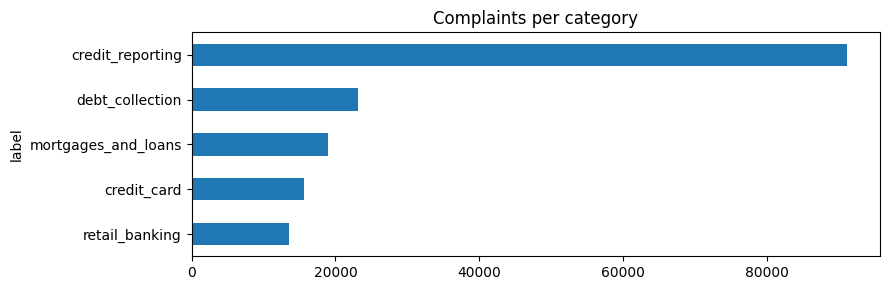

classes kept: 5 | rows: 162411


In [2]:
counts = data["label"].value_counts()
distribution = counts.to_frame("count")
distribution["percent"] = (counts / counts.sum() * 100).round(2)
display(distribution)
print(f"imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}")

fig, axis = plt.subplots(figsize=(9, max(3, 0.45 * len(counts))))
counts.sort_values().plot.barh(ax=axis, color="tab:blue")
axis.set_title("Complaints per category")
plt.tight_layout()
plt.show()

kept_classes = counts[counts >= MIN_CLASS_SAMPLES].index
dropped = counts[counts < MIN_CLASS_SAMPLES]
if len(dropped):
    print("classes removed (fewer than", MIN_CLASS_SAMPLES, "samples):", dropped.to_dict())
data = data[data["label"].isin(kept_classes)].reset_index(drop=True)
print("classes kept:", len(kept_classes), "| rows:", len(data))

## 3. Preprocess the text
Two versions of each complaint are prepared. The recurrent models use the fully cleaned text (lowercase, no punctuation, numbers, or special characters, no stop words, lemmatized). The transformer uses a lightly cleaned version, because pretrained transformers work best with natural sentences. The redaction markers (`XXXX`) used in this dataset are removed from both.

In [3]:
try:
    import nltk
    for package in ("stopwords", "wordnet", "omw-1.4"):
        nltk.download(package, quiet=True)
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer
    STOP_WORDS = set(stopwords.words("english"))
    lemmatizer = WordNetLemmatizer()
    lemmatizer.lemmatize("tests")
    LEMMATIZE = True
except Exception as error:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    STOP_WORDS = set(ENGLISH_STOP_WORDS)
    LEMMATIZE = False
    print("NLTK data unavailable, lemmatization skipped:", error)
print("stop words:", len(STOP_WORDS), "| lemmatization:", LEMMATIZE)

URL_RE = re.compile(r"https?://\S+|www\.\S+")
REDACTED_RE = re.compile(r"\b[xX]{2,}(?:[/\-][xX]{2,})*\b")
NON_LETTER_RE = re.compile(r"[^a-z\s]")
SPACES_RE = re.compile(r"\s+")
lemma_cache = {}

def lemma(word):
    cached = lemma_cache.get(word)
    if cached is None:
        cached = lemmatizer.lemmatize(lemmatizer.lemmatize(word), pos="v") if LEMMATIZE else word
        lemma_cache[word] = cached
    return cached

def clean_for_rnn(text):
    text = URL_RE.sub(" ", text.lower())
    text = REDACTED_RE.sub(" ", text)
    text = NON_LETTER_RE.sub(" ", text)
    words = [lemma(w) for w in text.split() if len(w) > 1 and w not in STOP_WORDS]
    return " ".join(words)

def clean_for_transformer(text):
    text = URL_RE.sub(" ", text)
    text = REDACTED_RE.sub(" ", text)
    return SPACES_RE.sub(" ", text).strip()

data["text_rnn"] = [clean_for_rnn(t) for t in data["text"]]
data["text_tr"] = [clean_for_transformer(t) for t in data["text"]]

before = len(data)
data = data[data["text_rnn"].str.split().str.len() >= MIN_TOKENS]
data = data.drop_duplicates(subset="text_rnn").reset_index(drop=True)
print(f"rows removed (too short or duplicate after cleaning): {before - len(data)} | remaining: {len(data)}")

for i in range(3):
    row = data.sample(1, random_state=SEED + i).iloc[0]
    print("\nCATEGORY:", row["label"])
    print("ORIGINAL   :", row["text"][:300])
    print("RNN INPUT  :", row["text_rnn"][:300])
    print("TRANSFORMER:", row["text_tr"][:300])

stop words: 198 | lemmatization: True
rows removed (too short or duplicate after cleaning): 39257 | remaining: 123154

CATEGORY: debt_collection
ORIGINAL   : deposited personal account check direction emloyer order conduct business behalf day deposit orig check amt account balance called corporate office spoke representative named assured fund appearing account balance cleared bank authorized use proceeded conduct business employer behalf attempted acces
RNN INPUT  : deposit personal account check direction emloyer order conduct business behalf day deposit orig check amt account balance call corporate office speak representative name assure fund appear account balance clear bank authorize use proceed conduct business employer behalf attempt access bank account d
TRANSFORMER: deposited personal account check direction emloyer order conduct business behalf day deposit orig check amt account balance called corporate office spoke representative named assured fund appearing account balance 

## 4. Split the data and handle class imbalance
The data is split into stratified train, validation, and test sets, so every class appears in each set with its natural proportion. Imbalance is handled on the training set in two ways: the largest classes are capped, and the loss uses class weights. Validation and test keep the natural distribution, so the reported scores reflect real use.

In [4]:
classes = sorted(data["label"].unique())
class_to_id = {name: i for i, name in enumerate(classes)}
data["y"] = data["label"].map(class_to_id)

train_val, test = train_test_split(data, test_size=TEST_FRACTION, stratify=data["y"], random_state=SEED)
train_full, val = train_test_split(train_val, test_size=VAL_FRACTION / (1 - TEST_FRACTION),
                                   stratify=train_val["y"], random_state=SEED + 1)

train = train_full.sample(frac=1, random_state=SEED).groupby("y").head(TRAIN_CAP_PER_CLASS).reset_index(drop=True)
if len(val) > EVAL_MAX:
    val = val.sample(EVAL_MAX, random_state=SEED)
if len(test) > EVAL_MAX:
    test = test.sample(EVAL_MAX, random_state=SEED)
val, test = val.reset_index(drop=True), test.reset_index(drop=True)

class_weight_values = compute_class_weight("balanced", classes=np.arange(len(classes)), y=train["y"].to_numpy())
class_weights = torch.tensor(class_weight_values, dtype=torch.float32, device=device)

overview = pd.DataFrame({
    "train (full)": train_full["label"].value_counts(),
    "train (used)": train["label"].value_counts(),
    "validation": val["label"].value_counts(),
    "test": test["label"].value_counts(),
    "class weight": pd.Series(class_weight_values, index=classes).round(2),
}).loc[classes]
display(overview)
print("train / validation / test:", len(train), len(val), len(test))

,train (full),train (used),validation,test,class weight
credit_card,11984,8000,1498,1498,1.0
credit_reporting,44009,8000,5501,5501,1.0
debt_collection,16797,8000,2100,2100,1.0
mortgages_and_loans,14974,8000,1872,1872,1.0
retail_banking,10758,8000,1345,1345,1.0


train / validation / test: 40000 12316 12316


## 5. Convert text to numerical sequences and pad them
A word tokenizer is fitted on the training text only. Every word becomes an integer id (`0` is padding, `1` is an unknown word). Sequences are then truncated or padded with zeros to the same length, and the true lengths are kept so the recurrent layers can ignore the padding.

In [5]:
PAD_ID, UNK_ID = 0, 1

class WordTokenizer:
    def __init__(self, vocab_size, min_freq):
        self.vocab_size = vocab_size
        self.min_freq = min_freq
        self.word_index = {}

    def fit(self, texts):
        counter = Counter(word for text in texts for word in text.split())
        words = [w for w, c in counter.most_common(self.vocab_size - 2) if c >= self.min_freq]
        self.word_index = {w: i + 2 for i, w in enumerate(words)}
        return self

    def texts_to_sequences(self, texts):
        return [[self.word_index.get(w, UNK_ID) for w in text.split()] for text in texts]

    @property
    def size(self):
        return len(self.word_index) + 2

def pad_sequences(sequences, max_len):
    padded = np.zeros((len(sequences), max_len), dtype=np.int64)
    lengths = np.ones(len(sequences), dtype=np.int64)
    for i, sequence in enumerate(sequences):
        sequence = sequence[:max_len]
        padded[i, :len(sequence)] = sequence
        lengths[i] = max(len(sequence), 1)
    return padded, lengths

tokenizer = WordTokenizer(VOCAB_SIZE, MIN_FREQ).fit(train["text_rnn"])
train_seq = tokenizer.texts_to_sequences(train["text_rnn"])
val_seq = tokenizer.texts_to_sequences(val["text_rnn"])
test_seq = tokenizer.texts_to_sequences(test["text_rnn"])

X_train, L_train = pad_sequences(train_seq, MAX_LEN)
X_val, L_val = pad_sequences(val_seq, MAX_LEN)
X_test, L_test = pad_sequences(test_seq, MAX_LEN)
y_train, y_val, y_test = (d["y"].to_numpy().astype(np.int64) for d in (train, val, test))

lengths_all = np.asarray([len(s) for s in train_seq])
unknown_rate = np.mean([w == UNK_ID for seq in val_seq for w in seq])
print("vocabulary size:", tokenizer.size)
print(f"unknown-word rate on validation text: {unknown_rate:.2%}")
print(f"sequence length percentiles 50/90/95/99: {np.percentile(lengths_all, [50, 90, 95, 99]).astype(int).tolist()}")
print(f"complaints longer than MAX_LEN={MAX_LEN}: {np.mean(lengths_all > MAX_LEN):.1%}")
print("example text   :", train["text_rnn"].iloc[0][:150])
print("example ids    :", X_train[0][:20].tolist())
print("padded shape   :", X_train.shape)

def make_loader(X, lengths, y, batch_size, shuffle):
    dataset = torch.utils.data.TensorDataset(torch.from_numpy(X), torch.from_numpy(lengths), torch.from_numpy(y))
    return torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train, L_train, y_train, RNN_BATCH, True)
val_loader = make_loader(X_val, L_val, y_val, 512, False)
test_loader = make_loader(X_test, L_test, y_test, 512, False)

vocabulary size: 11186
unknown-word rate on validation text: 0.59%
sequence length percentiles 50/90/95/99: [63, 189, 264, 513]
complaints longer than MAX_LEN=200: 8.9%
example text   : hi try make purchase online usual citibank fraud dept block card put account review unknown reason even though call make sure payment go successfully 
example ids    : [1192, 49, 14, 89, 124, 1781, 259, 88, 521, 308, 10, 149, 2, 206, 721, 170, 67, 282, 5, 14]
padded shape   : (40000, 200)


## 6. Build the embedding layer and the recurrent models
All three recurrent models share the same architecture and differ only in the recurrent cell: an embedding layer turns each word id into a dense vector, a bidirectional recurrent layer reads the sequence (padding is skipped with packed sequences), mean and max pooling summarize the outputs, and a dense layer predicts the category.

In [6]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class RecurrentClassifier(nn.Module):
    def __init__(self, cell, vocab_size, num_classes, embed_dim, hidden, dropout, bidirectional):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        recurrent = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[cell]
        extra = {"nonlinearity": "tanh"} if cell == "rnn" else {}
        self.rnn = recurrent(embed_dim, hidden, batch_first=True, bidirectional=bidirectional, **extra)
        width = hidden * (2 if bidirectional else 1)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(width * 2, num_classes)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        output, _ = self.rnn(packed)
        output, _ = pad_packed_sequence(output, batch_first=True, total_length=x.size(1))
        mask = (torch.arange(x.size(1), device=x.device)[None, :] < lengths[:, None]).unsqueeze(-1)
        mean_pool = (output * mask).sum(dim=1) / lengths.unsqueeze(1).float()
        max_pool = output.masked_fill(~mask, -1e9).max(dim=1).values
        return self.classifier(self.dropout(torch.cat([mean_pool, max_pool], dim=1)))

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

def copy_state(model):
    return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def score_probs(probs, targets):
    predictions = probs.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(targets, predictions, average="macro", zero_division=0)
    weighted_f1 = precision_recall_fscore_support(targets, predictions, average="weighted", zero_division=0)[2]
    loss = float(-np.log(np.clip(probs[np.arange(len(targets)), targets], 1e-8, 1.0)).mean())
    return {"accuracy": float(accuracy_score(targets, predictions)), "precision": float(precision),
            "recall": float(recall), "f1": float(f1), "weighted_f1": float(weighted_f1), "loss": loss}

@torch.no_grad()
def recurrent_probs(model, loader):
    model.eval()
    outputs = []
    for x, lengths, _ in loader:
        logits = model(x.to(device), lengths.to(device))
        outputs.append(F.softmax(logits.float(), dim=1).cpu())
    return torch.cat(outputs).numpy()

results = {}

def register_result(key, label, history, train_seconds, params, val_probs, test_fn):
    started = time.time()
    test_probs = test_fn()
    elapsed = time.time() - started
    results[key] = {
        "label": label, "history": history, "train_seconds": train_seconds, "params": params,
        "val_probs": val_probs, "test_probs": test_probs, "samples_per_second": len(y_test) / elapsed,
        "val": score_probs(val_probs, y_val), "test": score_probs(test_probs, y_test),
    }
    r = results[key]
    print(f"{label}: val F1 {r['val']['f1']:.4f} | test accuracy {r['test']['accuracy']:.4f} | test macro-F1 {r['test']['f1']:.4f} "
          f"| train {train_seconds / 60:.1f} min | {r['samples_per_second']:.0f} samples/s")

def train_recurrent(cell, label):
    set_seed(SEED)
    model = RecurrentClassifier(cell, tokenizer.size, len(classes), EMBED_DIM, HIDDEN, DROPOUT, BIDIRECTIONAL).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=RNN_LR)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    print(f"{label}: {count_parameters(model):,} parameters")
    history, best_f1, best_state, waiting = [], -1.0, None, 0
    started = time.time()
    for epoch in range(1, RNN_EPOCHS + 1):
        model.train()
        running = 0.0
        for x, lengths, y in train_loader:
            x, lengths, y = x.to(device), lengths.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x, lengths), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running += loss.item()
        val_scores = score_probs(recurrent_probs(model, val_loader), y_val)
        history.append({"epoch": epoch, "train_loss": running / len(train_loader), "val_loss": val_scores["loss"],
                        "val_accuracy": val_scores["accuracy"], "val_f1": val_scores["f1"]})
        print(f"{label} {epoch:>2}/{RNN_EPOCHS} | train loss {running / len(train_loader):.4f} | val loss {val_scores['loss']:.4f} "
              f"| val acc {val_scores['accuracy']:.4f} | val F1 {val_scores['f1']:.4f}")
        if val_scores["f1"] > best_f1:
            best_f1, best_state, waiting = val_scores["f1"], copy_state(model), 0
        else:
            waiting += 1
            if waiting >= PATIENCE:
                print("Early stopping")
                break
    train_seconds = time.time() - started
    model.load_state_dict(best_state)
    model.eval()
    register_result(cell, label, history, train_seconds, count_parameters(model),
                    recurrent_probs(model, val_loader), lambda: recurrent_probs(model, test_loader))
    return model

models = {}
print(RecurrentClassifier("gru", tokenizer.size, len(classes), EMBED_DIM, HIDDEN, DROPOUT, BIDIRECTIONAL))

RecurrentClassifier(
  (embedding): Embedding(11186, 128, padding_idx=0)
  (rnn): GRU(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=512, out_features=5, bias=True)
)


## 7. Train the SimpleRNN

In [7]:
models["rnn"] = train_recurrent("rnn", "SimpleRNN")

SimpleRNN: 1,500,421 parameters
SimpleRNN  1/8 | train loss 0.8099 | val loss 0.6732 | val acc 0.7683 | val F1 0.7586
SimpleRNN  2/8 | train loss 0.6074 | val loss 0.6653 | val acc 0.7692 | val F1 0.7633
SimpleRNN  3/8 | train loss 0.5461 | val loss 0.6336 | val acc 0.7788 | val F1 0.7766
SimpleRNN  4/8 | train loss 0.5108 | val loss 0.6131 | val acc 0.7930 | val F1 0.7861
SimpleRNN  5/8 | train loss 0.4873 | val loss 0.6063 | val acc 0.7936 | val F1 0.7885
SimpleRNN  6/8 | train loss 0.4619 | val loss 0.5561 | val acc 0.8116 | val F1 0.8020
SimpleRNN  7/8 | train loss 0.4448 | val loss 0.5662 | val acc 0.8134 | val F1 0.8013
SimpleRNN  8/8 | train loss 0.4265 | val loss 0.6648 | val acc 0.7781 | val F1 0.7779
SimpleRNN: val F1 0.8020 | test accuracy 0.8154 | test macro-F1 0.8067 | train 2.4 min | 25661 samples/s


## 8. Train the LSTM

In [8]:
models["lstm"] = train_recurrent("lstm", "LSTM")

LSTM: 1,698,565 parameters
LSTM  1/8 | train loss 0.6987 | val loss 0.5401 | val acc 0.8054 | val F1 0.7937
LSTM  2/8 | train loss 0.4976 | val loss 0.5048 | val acc 0.8193 | val F1 0.8096
LSTM  3/8 | train loss 0.4450 | val loss 0.4978 | val acc 0.8231 | val F1 0.8131
LSTM  4/8 | train loss 0.4110 | val loss 0.5105 | val acc 0.8197 | val F1 0.8154
LSTM  5/8 | train loss 0.3820 | val loss 0.4807 | val acc 0.8298 | val F1 0.8231
LSTM  6/8 | train loss 0.3546 | val loss 0.4834 | val acc 0.8306 | val F1 0.8221
LSTM  7/8 | train loss 0.3291 | val loss 0.4941 | val acc 0.8343 | val F1 0.8253
LSTM  8/8 | train loss 0.3071 | val loss 0.5212 | val acc 0.8305 | val F1 0.8201
LSTM: val F1 0.8253 | test accuracy 0.8362 | test macro-F1 0.8281 | train 2.5 min | 23520 samples/s


## 9. Train the GRU

In [9]:
models["gru"] = train_recurrent("gru", "GRU")

GRU: 1,632,517 parameters
GRU  1/8 | train loss 0.6857 | val loss 0.5614 | val acc 0.8004 | val F1 0.7959
GRU  2/8 | train loss 0.4894 | val loss 0.4827 | val acc 0.8242 | val F1 0.8138
GRU  3/8 | train loss 0.4377 | val loss 0.4709 | val acc 0.8308 | val F1 0.8198
GRU  4/8 | train loss 0.4023 | val loss 0.4689 | val acc 0.8312 | val F1 0.8213
GRU  5/8 | train loss 0.3695 | val loss 0.4992 | val acc 0.8263 | val F1 0.8185
GRU  6/8 | train loss 0.3396 | val loss 0.5433 | val acc 0.8191 | val F1 0.8128
GRU  7/8 | train loss 0.3187 | val loss 0.5421 | val acc 0.8229 | val F1 0.8150
Early stopping
GRU: val F1 0.8213 | test accuracy 0.8364 | test macro-F1 0.8282 | train 2.2 min | 25392 samples/s


## 10. Fine-tune the HuggingFace transformer
A pretrained DistilBERT is fine-tuned end to end on the same training data with the same class weights, using mixed precision, warmup, and linear learning-rate decay. The best epoch on validation data is kept.

In [12]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

tr_tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_NAME)

def encode(texts):
    return tr_tokenizer(list(texts), truncation=True, max_length=TR_MAX_LEN)

class EncodedDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.input_ids = encodings["input_ids"]
        self.attention_mask = encodings["attention_mask"]
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return {"input_ids": self.input_ids[i], "attention_mask": self.attention_mask[i], "labels": int(self.labels[i])}

def collate(batch):
    padded = tr_tokenizer.pad([{"input_ids": b["input_ids"], "attention_mask": b["attention_mask"]} for b in batch],
                              return_tensors="pt")
    padded["labels"] = torch.tensor([b["labels"] for b in batch], dtype=torch.long)
    return padded

started = time.time()
tr_train = EncodedDataset(encode(train["text_tr"]), y_train)
tr_val = EncodedDataset(encode(val["text_tr"]), y_val)
tr_test = EncodedDataset(encode(test["text_tr"]), y_test)
print(f"tokenized in {time.time() - started:.0f}s")

tr_train_loader = torch.utils.data.DataLoader(tr_train, batch_size=TR_BATCH, shuffle=True, collate_fn=collate)
tr_val_loader = torch.utils.data.DataLoader(tr_val, batch_size=64, shuffle=False, collate_fn=collate)
tr_test_loader = torch.utils.data.DataLoader(tr_test, batch_size=64, shuffle=False, collate_fn=collate)

@torch.no_grad()
def transformer_probs(model, loader):
    model.eval()
    outputs = []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        with torch.autocast("cuda", dtype=torch.float16, enabled=CUDA):
            logits = model(**batch).logits
        outputs.append(F.softmax(logits.float(), dim=1).cpu())
    return torch.cat(outputs).numpy()

def train_transformer():
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(TRANSFORMER_NAME, num_labels=len(classes)).to(device)
    print(f"{TRANSFORMER_NAME}: {count_parameters(model):,} parameters")
    no_decay = ("bias", "LayerNorm.weight")
    grouped = [
        {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], "weight_decay": 0.01},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)], "weight_decay": 0.0},
    ]
    optimizer = torch.optim.AdamW(grouped, lr=TR_LR)
    total_steps = len(tr_train_loader) * TR_EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=CUDA)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    history, best_f1, best_state = [], -1.0, None
    started = time.time()
    for epoch in range(1, TR_EPOCHS + 1):
        model.train()
        running = 0.0
        for step, batch in enumerate(tr_train_loader, start=1):
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")
            with torch.autocast("cuda", dtype=torch.float16, enabled=CUDA):
                logits = model(**batch).logits
            loss = criterion(logits.float(), labels)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item()
            if step % 500 == 0:
                print(f"  epoch {epoch} step {step}/{len(tr_train_loader)} | loss {running / step:.4f}")
        val_scores = score_probs(transformer_probs(model, tr_val_loader), y_val)
        history.append({"epoch": epoch, "train_loss": running / len(tr_train_loader), "val_loss": val_scores["loss"],
                        "val_accuracy": val_scores["accuracy"], "val_f1": val_scores["f1"]})
        print(f"Transformer {epoch}/{TR_EPOCHS} | train loss {running / len(tr_train_loader):.4f} | val loss {val_scores['loss']:.4f} "
              f"| val acc {val_scores['accuracy']:.4f} | val F1 {val_scores['f1']:.4f} | {(time.time() - started) / 60:.1f} min")
        if val_scores["f1"] > best_f1:
            best_f1, best_state = val_scores["f1"], copy_state(model)
    train_seconds = time.time() - started
    model.load_state_dict(best_state)
    model.eval()
    register_result("transformer", "Fine-tuned DistilBERT", history, train_seconds, count_parameters(model),
                    transformer_probs(model, tr_val_loader), lambda: transformer_probs(model, tr_test_loader))
    return model

models["transformer"] = train_transformer()

tokenized in 12s


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


distilbert-base-uncased: 66,957,317 parameters
  epoch 1 step 500/2500 | loss 0.9753
  epoch 1 step 1000/2500 | loss 0.7702
  epoch 1 step 1500/2500 | loss 0.6781
  epoch 1 step 2000/2500 | loss 0.6271
  epoch 1 step 2500/2500 | loss 0.5977
Transformer 1/2 | train loss 0.5977 | val loss 0.4809 | val acc 0.8310 | val F1 0.8252 | 4.8 min
  epoch 2 step 500/2500 | loss 0.3952
  epoch 2 step 1000/2500 | loss 0.3789
  epoch 2 step 1500/2500 | loss 0.3747
  epoch 2 step 2000/2500 | loss 0.3723
  epoch 2 step 2500/2500 | loss 0.3701
Transformer 2/2 | train loss 0.3701 | val loss 0.4604 | val acc 0.8400 | val F1 0.8349 | 9.5 min
Fine-tuned DistilBERT: val F1 0.8349 | test accuracy 0.8428 | test macro-F1 0.8376 | train 9.5 min | 546 samples/s


## 11. Evaluate the models: accuracy, precision, recall, F1, confusion matrix
Precision, recall, and F1 are macro averages, so each category counts equally regardless of its size. Weighted F1 is added because it reflects the natural class distribution.

SimpleRNN
                     precision    recall  f1-score   support

        credit_card      0.688     0.812     0.745      1498
   credit_reporting      0.921     0.783     0.846      5501
    debt_collection      0.714     0.811     0.759      2100
mortgages_and_loans      0.808     0.865     0.836      1872
     retail_banking      0.809     0.888     0.847      1345

           accuracy                          0.815     12316
          macro avg      0.788     0.832     0.807     12316
       weighted avg      0.828     0.815     0.818     12316

LSTM
                     precision    recall  f1-score   support

        credit_card      0.722     0.836     0.775      1498
   credit_reporting      0.929     0.811     0.866      5501
    debt_collection      0.735     0.836     0.782      2100
mortgages_and_loans      0.824     0.869     0.846      1872
     retail_banking      0.850     0.894     0.872      1345

           accuracy                          0.836     12316
    

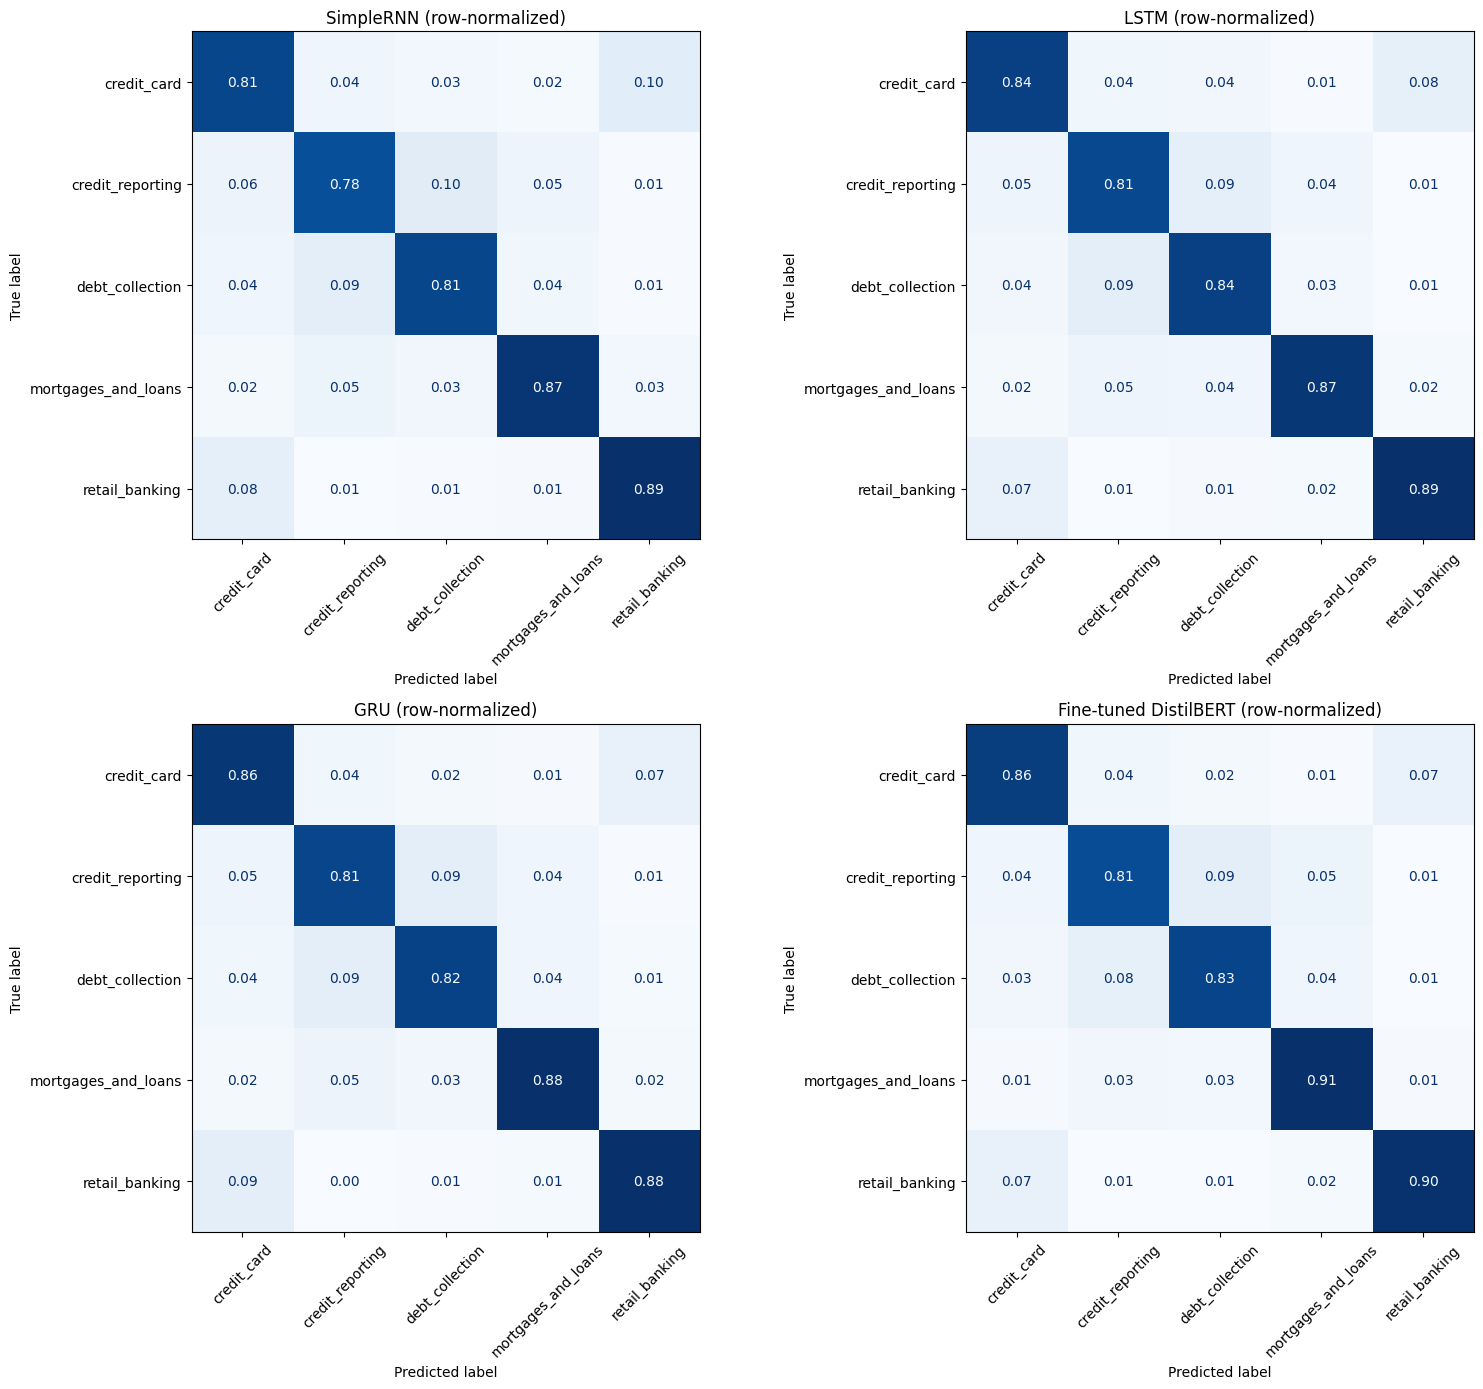

In [13]:
for key, r in results.items():
    predictions = r["test_probs"].argmax(axis=1)
    print("=" * 80)
    print(r["label"])
    print(classification_report(y_test, predictions, target_names=classes, digits=3, zero_division=0))

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for axis, (key, r) in zip(axes.flat, results.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, r["test_probs"].argmax(axis=1), display_labels=classes, normalize="true",
        xticks_rotation=45, cmap="Blues", colorbar=False, values_format=".2f", ax=axis)
    axis.set_title(f"{r['label']} (row-normalized)")
plt.tight_layout()
plt.show()

## 12. Compare the four models
The validation set chooses the deployment model. The test results are the final comparison.

,model,test accuracy,test precision (macro),test recall (macro),test F1 (macro),test F1 (weighted),val F1 (macro),parameters (M),train time (min),inference (samples/s)
0,Fine-tuned DistilBERT,0.8428,0.8202,0.8608,0.8376,0.8443,0.8349,66.9573,9.5395,545.6610
1,LSTM,0.8362,0.8120,0.8493,0.8281,0.8382,0.8253,1.6986,2.5065,23520.3220
2,GRU,0.8364,0.8115,0.8500,0.8282,0.8381,0.8213,1.6325,2.1654,25391.9850
3,SimpleRNN,0.8154,0.7879,0.8321,0.8067,0.8176,0.8020,1.5004,2.3733,25661.2894


best model on validation macro-F1: Fine-tuned DistilBERT


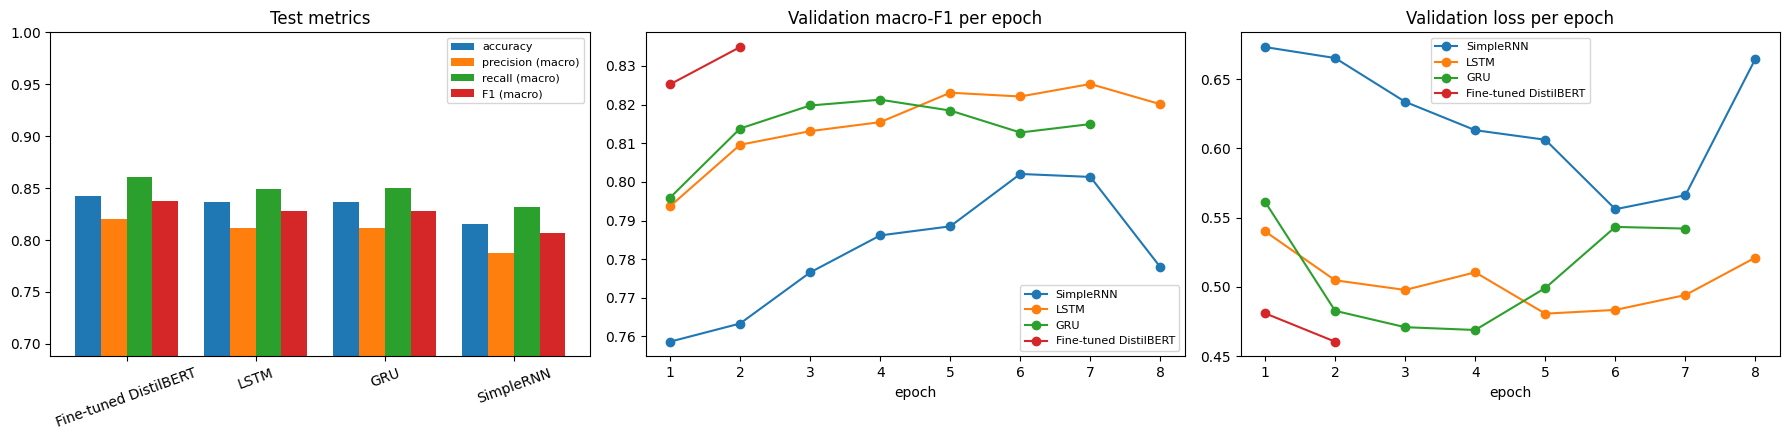

1) Best test macro-F1: Fine-tuned DistilBERT (0.838); model chosen on validation: Fine-tuned DistilBERT.
2) Among the models built from scratch: GRU (0.828) > LSTM (0.828) > SimpleRNN (0.807).
3) Transformer vs best custom model (GRU): +0.9 macro-F1 points, 4.4x training time, 46.5x faster inference for the custom model.
4) Accuracy vs macro-F1: the best model has 0.843 accuracy but 0.838 macro-F1; the gap shows how much the smaller classes cost.
5) Most frequent confusion of the best model: true 'credit_reporting' predicted as 'debt_collection' (510 complaints).
6) Caveat: results come from one split and one seed with 12316 test complaints; small differences between models are within noise.


In [14]:
rows = []
for key, r in results.items():
    rows.append({
        "model": r["label"], "test accuracy": r["test"]["accuracy"], "test precision (macro)": r["test"]["precision"],
        "test recall (macro)": r["test"]["recall"], "test F1 (macro)": r["test"]["f1"], "test F1 (weighted)": r["test"]["weighted_f1"],
        "val F1 (macro)": r["val"]["f1"], "parameters (M)": r["params"] / 1e6,
        "train time (min)": r["train_seconds"] / 60, "inference (samples/s)": r["samples_per_second"], "key": key,
    })
comparison = pd.DataFrame(rows).sort_values("val F1 (macro)", ascending=False).reset_index(drop=True)
display(comparison.drop(columns="key").round(4))

best_key = comparison.loc[0, "key"]
print("best model on validation macro-F1:", results[best_key]["label"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
metrics = ["test accuracy", "test precision (macro)", "test recall (macro)", "test F1 (macro)"]
x = np.arange(len(comparison))
for k, metric in enumerate(metrics):
    axes[0].bar(x + (k - 1.5) * 0.2, comparison[metric], 0.2, label=metric.replace("test ", ""))
axes[0].set_xticks(x)
axes[0].set_xticklabels(comparison["model"], rotation=20)
axes[0].set_ylim(max(0, comparison[metrics].min().min() - 0.1), 1.0)
axes[0].set_title("Test metrics")
axes[0].legend(fontsize=8)
for key, r in results.items():
    epochs = [h["epoch"] for h in r["history"]]
    axes[1].plot(epochs, [h["val_f1"] for h in r["history"]], marker="o", label=r["label"])
    axes[2].plot(epochs, [h["val_loss"] for h in r["history"]], marker="o", label=r["label"])
axes[1].set_title("Validation macro-F1 per epoch")
axes[2].set_title("Validation loss per epoch")
for axis in axes[1:]:
    axis.set_xlabel("epoch")
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

ordered = comparison.sort_values("test F1 (macro)", ascending=False).reset_index(drop=True)
rnn_rows = comparison[comparison["key"].isin(["rnn", "lstm", "gru"])].sort_values("test F1 (macro)", ascending=False)
transformer_row = comparison[comparison["key"] == "transformer"].iloc[0]
best_custom = rnn_rows.iloc[0]
print(f"1) Best test macro-F1: {ordered.loc[0, 'model']} ({ordered.loc[0, 'test F1 (macro)']:.3f}); "
      f"model chosen on validation: {results[best_key]['label']}.")
print(f"2) Among the models built from scratch: " + " > ".join(f"{r['model']} ({r['test F1 (macro)']:.3f})" for _, r in rnn_rows.iterrows()) + ".")
print(f"3) Transformer vs best custom model ({best_custom['model']}): "
      f"{(transformer_row['test F1 (macro)'] - best_custom['test F1 (macro)']) * 100:+.1f} macro-F1 points, "
      f"{transformer_row['train time (min)'] / max(best_custom['train time (min)'], 1e-9):.1f}x training time, "
      f"{best_custom['inference (samples/s)'] / max(transformer_row['inference (samples/s)'], 1e-9):.1f}x faster inference for the custom model.")
print(f"4) Accuracy vs macro-F1: the best model has {ordered.loc[0, 'test accuracy']:.3f} accuracy but {ordered.loc[0, 'test F1 (macro)']:.3f} macro-F1; "
      "the gap shows how much the smaller classes cost.")
best_matrix = confusion_matrix(y_test, results[ordered.loc[0, "key"]]["test_probs"].argmax(axis=1), labels=np.arange(len(classes)))
off_diagonal = best_matrix.copy()
np.fill_diagonal(off_diagonal, 0)
if off_diagonal.max() > 0:
    a, b = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"5) Most frequent confusion of the best model: true '{classes[a]}' predicted as '{classes[b]}' ({off_diagonal[a, b]} complaints).")
print(f"6) Caveat: results come from one split and one seed with {len(test)} test complaints; small differences between models are within noise.")

## 13. Classify new complaints with the best model and measure routing automation
The best model scores new complaints with a predicted category and a confidence. The confidence table shows how many complaints could be routed automatically at each threshold and how accurate those automatic decisions are on the test set, with the rest going to a person.

In [15]:
@torch.no_grad()
def predict_proba(model_key, texts):
    texts = [str(t) for t in texts]
    model = models[model_key]
    model.eval()
    if model_key == "transformer":
        loader = torch.utils.data.DataLoader(
            EncodedDataset(encode([clean_for_transformer(t) for t in texts]), np.zeros(len(texts), dtype=np.int64)),
            batch_size=32, shuffle=False, collate_fn=collate)
        return transformer_probs(model, loader)
    sequences = tokenizer.texts_to_sequences([clean_for_rnn(t) for t in texts])
    X, lengths = pad_sequences(sequences, MAX_LEN)
    loader = make_loader(X, lengths, np.zeros(len(texts), dtype=np.int64), 256, False)
    return recurrent_probs(model, loader)

def classify(texts, model_key=None):
    probs = predict_proba(model_key or best_key, texts)
    return [{"category": classes[int(p.argmax())], "confidence": float(p.max())} for p in probs]

new_complaints = [
    "I found accounts on my credit report that I never opened and the credit bureau refuses to remove them even after I sent proof.",
    "A collection agency keeps calling me every day about a debt I already paid and they threaten to sue me.",
    "My mortgage servicer lost my payment and charged me late fees, and now they are reporting me as delinquent.",
    "My credit card company charged me an annual fee after I cancelled the card and they will not refund it.",
    "The bank closed my checking account without notice and is holding my money, and nobody at the branch can explain why.",
]
for text, prediction in zip(new_complaints, classify(new_complaints)):
    print(f"{prediction['category']:<30} {prediction['confidence']:.1%}  |  {text[:90]}")

best_probs = results[best_key]["test_probs"]
confidence = best_probs.max(axis=1)
correct = best_probs.argmax(axis=1) == y_test
threshold_rows = []
for threshold in (0.0, 0.5, 0.7, 0.8, 0.9, 0.95):
    selected = confidence >= threshold
    threshold_rows.append({
        "confidence threshold": threshold,
        "routed automatically": f"{selected.mean():.1%}",
        "accuracy of automatic decisions": f"{correct[selected].mean():.1%}" if selected.any() else "-",
        "sent to a person": f"{1 - selected.mean():.1%}",
    })
display(pd.DataFrame(threshold_rows))

credit_reporting               68.9%  |  I found accounts on my credit report that I never opened and the credit bureau refuses to 
debt_collection                98.0%  |  A collection agency keeps calling me every day about a debt I already paid and they threat
mortgages_and_loans            62.6%  |  My mortgage servicer lost my payment and charged me late fees, and now they are reporting 
credit_card                    96.3%  |  My credit card company charged me an annual fee after I cancelled the card and they will n
retail_banking                 96.2%  |  The bank closed my checking account without notice and is holding my money, and nobody at 


,confidence threshold,routed automatically,accuracy of automatic decisions,sent to a person
0,0.00,100.0%,84.3%,0.0%
1,0.50,97.3%,85.5%,2.7%
2,0.70,87.5%,89.2%,12.5%
3,0.80,80.9%,91.2%,19.1%
4,0.90,70.6%,93.7%,29.4%
5,0.95,59.0%,95.8%,41.0%


## 14. Save the best model

In [16]:
WORK = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./working")
WORK.mkdir(parents=True, exist_ok=True)

comparison.drop(columns="key").to_csv(WORK / "model_comparison.csv", index=False)
(WORK / "classes.json").write_text(json.dumps(classes))

if best_key == "transformer":
    SAVE_DIR = WORK / "best_transformer"
    models["transformer"].save_pretrained(SAVE_DIR)
    tr_tokenizer.save_pretrained(SAVE_DIR)
    print("transformer saved to", SAVE_DIR)
else:
    SAVE_PATH = WORK / "best_recurrent_model.pt"
    torch.save({
        "cell": best_key, "state_dict": copy_state(models[best_key]), "classes": classes, "word_index": tokenizer.word_index,
        "config": {"vocab_size": tokenizer.size, "embed_dim": EMBED_DIM, "hidden": HIDDEN, "dropout": DROPOUT,
                   "bidirectional": BIDIRECTIONAL, "max_len": MAX_LEN},
    }, SAVE_PATH)
    print("recurrent model saved to", SAVE_PATH, f"({SAVE_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"total notebook runtime: {(time.time() - T0) / 60:.1f} min")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

transformer saved to /kaggle/working/best_transformer
total notebook runtime: 45.4 min


## 15. Deploy the best model with Gradio
The app takes a complaint narrative and returns the predicted category with a confidence score and the probability of every category.

In [17]:
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr

def predict_complaint(text):
    if text is None or not text.strip():
        return {}, "Enter a complaint to classify."
    probs = predict_proba(best_key, [text])[0]
    ranking = {classes[i]: float(probs[i]) for i in range(len(classes))}
    top = int(probs.argmax())
    return ranking, f"Predicted category: {classes[top]}\nConfidence: {probs[top]:.1%}"

demo = gr.Interface(
    fn=predict_complaint,
    inputs=gr.Textbox(lines=8, label="Customer complaint narrative", placeholder="Describe the complaint here..."),
    outputs=[gr.Label(num_top_classes=len(classes), label="Category probabilities"), gr.Textbox(label="Prediction")],
    title="Customer Complaint Classifier",
    description=f"Predicts the complaint category with {results[best_key]['label']}.",
    examples=[[t] for t in new_complaints[:3]],
)
try:
    demo.launch(share=True, prevent_thread_lock=True)
except Exception as error:
    print("share link unavailable:", error)
    demo.launch(prevent_thread_lock=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://2289296f9c06837dc8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
